<h1>Содержание<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Подготовка" data-toc-modified-id="Подготовка-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Подготовка</a></span></li><li><span><a href="#Обучение" data-toc-modified-id="Обучение-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Обучение</a></span></li><li><span><a href="#Выводы" data-toc-modified-id="Выводы-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Выводы</a></span></li></ul></div>

# Проект для «Викишоп»

Интернет-магазин «Викишоп» запускает новый сервис. Теперь пользователи могут редактировать и дополнять описания товаров, как в вики-сообществах. То есть клиенты предлагают свои правки и комментируют изменения других. Магазину нужен инструмент, который будет искать токсичные комментарии и отправлять их на модерацию. 

Обучите модель классифицировать комментарии на позитивные и негативные. В вашем распоряжении набор данных с разметкой о токсичности правок.

Постройте модель со значением метрики качества *F1* не меньше 0.75. 

**Инструкция по выполнению проекта**

1. Загрузите и подготовьте данные.
2. Обучите разные модели. 
3. Сделайте выводы.

Для выполнения проекта применять *BERT* необязательно, но вы можете попробовать.

**Описание данных**

Данные находятся в файле `toxic_comments.csv`. Столбец *text* в нём содержит текст комментария, а *toxic* — целевой признак.

## Подготовка

In [1]:
#Загрузим все необходимые библиотеки
import pandas as pd
import numpy as np
import os

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import PassiveAggressiveClassifier
from sklearn.feature_extraction.text import TfidfVectorizer 
from sklearn.feature_extraction.text import CountVectorizer 
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import cross_val_score

import re 
import nltk
from nltk.corpus import stopwords as nltk_stopwords
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer 
from pymystem3 import Mystem
#from langdetect import detect

In [2]:
#Скачаем нужные данные для работы
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('stopwords')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\dakys\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\dakys\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\dakys\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [3]:
#Загрузим данные, больше 10000 строк загрузить не выходит, при работе ядро постоянно падает,
#Поэтому модели были обучены на 10000 событиях
pth1 = 'toxic_comments.csv'
pth2 = '/datasets/toxic_comments.csv'

if os.path.exists(pth1):
    df = pd.read_csv(pth1, nrows = 10000)
elif os.path.exists(pth2):
    df = pd.read_csv(pth2, nrows = 10000)
else:
    print('Something is wrong')
    

In [4]:
pd.set_option('display.max_colwidth', None)
df.head()

,Unnamed: 0,text,toxic
0,0,"Explanation\nWhy the edits made under my username Hardcore Metallica Fan were reverted? They weren't vandalisms, just closure on some GAs after I voted at New York Dolls FAC. And please don't remove the template from the talk page since I'm retired now.89.205.38.27",0
1,1,"D'aww! He matches this background colour I'm seemingly stuck with. Thanks. (talk) 21:51, January 11, 2016 (UTC)",0
2,2,"Hey man, I'm really not trying to edit war. It's just that this guy is constantly removing relevant information and talking to me through edits instead of my talk page. He seems to care more about the formatting than the actual info.",0
3,3,"""\nMore\nI can't make any real suggestions on improvement - I wondered if the section statistics should be later on, or a subsection of """"types of accidents"""" -I think the references may need tidying so that they are all in the exact same format ie date format etc. I can do that later on, if no-one else does first - if you have any preferences for formatting style on references or want to do it yourself please let me know.\n\nThere appears to be a backlog on articles for review so I guess there may be a delay until a reviewer turns up. It's listed in the relevant form eg Wikipedia:Good_article_nominations#Transport """,0
4,4,"You, sir, are my hero. Any chance you remember what page that's on?",0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  10000 non-null  int64 
 1   text        10000 non-null  object
 2   toxic       10000 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 234.5+ KB


Видно, что в датафрейме отсутствуют пустые строки, тип данных верный, Unnamed:0 - можно сделать индексом

In [6]:
#Напишем функицю для отрисовки графиков
def draw_graphics(df):
    fig1, ax1=plt.subplots(nrows=1, ncols=1, figsize=(8, 8))
    fig2, ax2=plt.subplots(nrows=1, ncols=1, figsize=(8, 8))
    sns.set_style("whitegrid")
    sns.histplot(x=df["Unnamed: 0"], ax=ax1)
    sns.countplot(x=df["toxic"], ax=ax2)
 
    ax1.set(ylabel='Количество событий', xlabel='Unnamed: 0', title="Unnamed: 0")
    ax2.set(ylabel='Количество событий', xlabel='Токсичность', title="toxic")

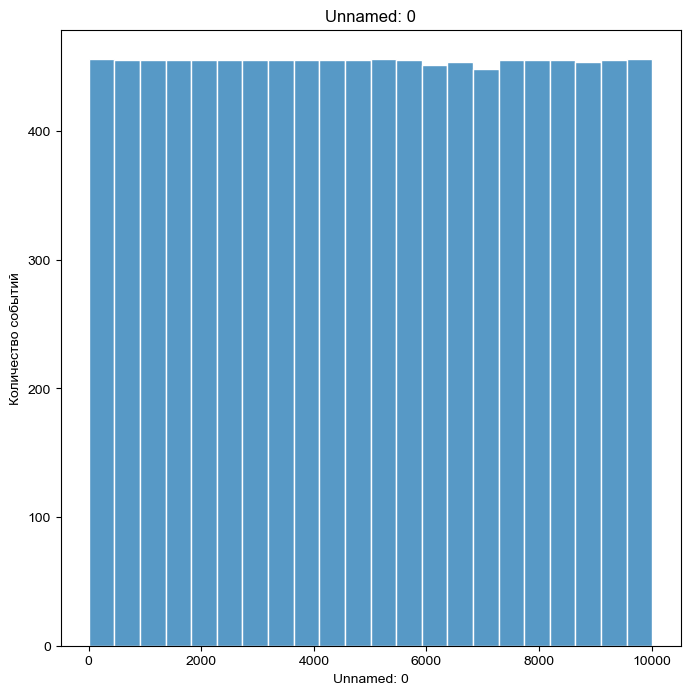

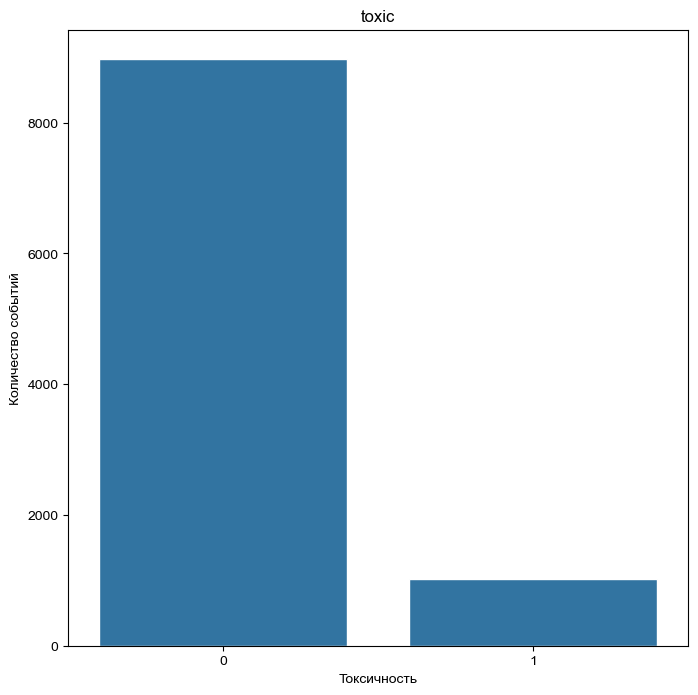

In [7]:
draw_graphics(df)

Распределение токсичности не равномерное, столбец unnamed:0 не нужен, избавимся от него, сделав его индексом

In [8]:
df["Unnamed: 0"].nunique()

10000

Видно, что все числа в этом столбце уникальные

In [9]:
df = df.set_index('Unnamed: 0')

In [10]:
df.head()

,text,toxic
Unnamed: 0,,
0,"Explanation\nWhy the edits made under my username Hardcore Metallica Fan were reverted? They weren't vandalisms, just closure on some GAs after I voted at New York Dolls FAC. And please don't remove the template from the talk page since I'm retired now.89.205.38.27",0
1,"D'aww! He matches this background colour I'm seemingly stuck with. Thanks. (talk) 21:51, January 11, 2016 (UTC)",0
2,"Hey man, I'm really not trying to edit war. It's just that this guy is constantly removing relevant information and talking to me through edits instead of my talk page. He seems to care more about the formatting than the actual info.",0
3,"""\nMore\nI can't make any real suggestions on improvement - I wondered if the section statistics should be later on, or a subsection of """"types of accidents"""" -I think the references may need tidying so that they are all in the exact same format ie date format etc. I can do that later on, if no-one else does first - if you have any preferences for formatting style on references or want to do it yourself please let me know.\n\nThere appears to be a backlog on articles for review so I guess there may be a delay until a reviewer turns up. It's listed in the relevant form eg Wikipedia:Good_article_nominations#Transport """,0
4,"You, sir, are my hero. Any chance you remember what page that's on?",0


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.isna().sum()

text     0
toxic    0
dtype: int64

Дубликатов и пустых строк в наших данных нет, можно начинать обучение

In [13]:
df['text'] = df['text'].str.lower()

In [14]:
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\dakys\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\dakys\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [15]:
#Подготовим данные для обучения модели
#Напишем функции для очистки текста и леммантизации слов



tag_dict = {"J": wordnet.ADJ,
            "N": wordnet.NOUN,
            "V": wordnet.VERB,
            "R": wordnet.ADV}

def get_wordnet_pos(word):
    tag = nltk.pos_tag([word])[0][1][0].upper()
    return tag_dict.get(tag, wordnet.NOUN)

lemmatizer = WordNetLemmatizer()

def lemmatize_wordnet(text):
    lemm_text = ' '.join([lemmatizer.lemmatize(w, get_wordnet_pos(w)) for w in nltk.word_tokenize(text)])
    return lemm_text


def clear_text(text):
    return " ".join(re.sub(r'[^а-яА-ЯёЁa-zA-Z]', ' ', text).split())

#Очищаем текст и лемантизируем слова
lemm_text = []
for i in df['text']:
    text = clear_text(i)
    lemm_text.append(lemmatize_wordnet(text))
    
df['text'] = lemm_text

In [16]:
df = df.rename(columns={'text': 'lemm_text'})

In [17]:
df.head()

,lemm_text,toxic
Unnamed: 0,,
0,explanation why the edits make under my username hardcore metallica fan be revert they weren t vandalism just closure on some gas after i vote at new york doll fac and please don t remove the template from the talk page since i m retire now,0
1,d aww he match this background colour i m seemingly stuck with thanks talk january utc,0
2,hey man i m really not try to edit war it s just that this guy be constantly remove relevant information and talk to me through edits instead of my talk page he seem to care more about the format than the actual info,0
3,more i can t make any real suggestion on improvement i wonder if the section statistic should be later on or a subsection of type of accident i think the reference may need tidy so that they be all in the exact same format ie date format etc i can do that later on if no one else do first if you have any preference for format style on reference or want to do it yourself please let me know there appear to be a backlog on article for review so i guess there may be a delay until a reviewer turn up it s list in the relevant form eg wikipedia good article nomination transport,0
4,you sir be my hero any chance you remember what page that s on,0


## Обучение

In [18]:
RANDOM_STATE = 42
TEST_SIZE = 0.1

X_train, X_test, y_train, y_test = train_test_split(
    df.drop('toxic', axis=1), 
    df['toxic'], 
    test_size = TEST_SIZE,
    random_state=RANDOM_STATE, stratify = df['toxic']
)

In [19]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9000 entries, 8338 to 2651
Data columns (total 1 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   lemm_text  9000 non-null   object
dtypes: object(1)
memory usage: 140.6+ KB


In [20]:
#Постриом входные признаки при помощи tf-idf
#stopwords = set(nltk_stopwords.words('russian', 'english'))
stopwords = list(nltk_stopwords.words('english'))

pipeline = Pipeline(
    [
        ("vect", TfidfVectorizer(stop_words=stopwords))
    ]
)

In [21]:
#Построим данные при помощи pipeline
tf_idf = pipeline.fit_transform(X_train['lemm_text'].values) 
df_tf = pd.DataFrame(
    data=tf_idf.toarray(),
    columns=pipeline['vect'].get_feature_names_out()
)
tf_idf_test = pipeline.transform(X_test['lemm_text'].values)
df_tf_test = pd.DataFrame(
    data=tf_idf_test.toarray(),
    columns=pipeline['vect'].get_feature_names_out()
)

Выберем лучшую модель для задачи при помощи кросс-валидации

In [22]:
clf = DecisionTreeClassifier(random_state = RANDOM_STATE, max_depth = 5)
metric_tree = cross_val_score(clf, df_tf, y_train, cv = 3, scoring = "f1").mean()
print(f'Значение метрики на кросс валидации для DecisionTreeClassifier: {metric_tree.round(3)}')

Значение метрики на кросс валидации для DecisionTreeClassifier: 0.509


In [23]:
clf = LogisticRegression(random_state=RANDOM_STATE, solver = 'liblinear', penalty = 'l1', C = 100., tol = 0.001)
metric_log = cross_val_score(clf, df_tf, y_train, cv = 3, scoring = "f1").mean()
print(f'Значение метрики на кросс валидации для LogisticRegression: {metric_log.round(3)}')

Значение метрики на кросс валидации для LogisticRegression: 0.689


In [24]:
clf = PassiveAggressiveClassifier(random_state = RANDOM_STATE)
metric_agr = cross_val_score(clf, df_tf, y_train, cv = 3, scoring = "f1").mean()
print(f'Значение метрики на кросс валидации для PassiveAggressiveClassifier: {metric_agr.round(3)}')

Значение метрики на кросс валидации для PassiveAggressiveClassifier: 0.691


Лучшей моделью является PassiveAggressiveClassifier, обучим её и проверим значение метрики на тестовых данных

In [25]:
metrics = [metric_tree, metric_log, metric_agr]
max_index = metrics.index(max(metrics))

if max_index == 0:
    clf = DecisionTreeClassifier(random_state = RANDOM_STATE, max_depth = 5)
elif max_index == 1:
    clf = LogisticRegression(random_state=RANDOM_STATE, solver = 'liblinear', penalty = 'l1', C = 100., tol = 0.001)
elif max_index == 2:
        clf = PassiveAggressiveClassifier(random_state = RANDOM_STATE)
        
clf.fit(df_tf, y_train);

In [26]:
model = clf
y_pred_test = model.predict(df_tf_test) 
print(f'{f1_score(y_test, y_pred_test):.3f}')

0.756


Тестирование данных показывает метрику, равную 0.76, что больше требуемых 0.75.

## Выводы

В работе была разработана модель машинного обучения для классификации комментариев на токсичность.

В первой главе была проведена подготовка данных. В силу ограничения по оперативной памяти (постоянное падение ядра Юпитера) была рассмотрена лишь часть полной статистики, при использовании большей статистики точность должна статистически расти. Данные были проверены на дубликаты и наличие пустых строк. Сами комментарии были очищены от ненужных символов, проведена была лемантизация слов.

Во второй главе было проведено обучение модели. Рассмотрены три модели DecisionTreeClassifier, LogisticRegression и PassiveAggressiveClassifier. При помощи кросс-валидации была выбрана лучшая модель в задаче (PassiveAggressiveClassifier). В результате проверки модели на тестовых данных была получена метрика f1 = 0.76.

Таким образом в работе была разработана модель машинного обучения, основанная на входных признаках, полученных методов tf_idf, дающим значение метрики f1 0.76.